# Лабораторная работа 1. Линейная регрессия

Выполнил Михаил Мышакин, группа М8О-312БВ-24

Задача — предсказать числовой балл кредитного риска RiskScore. Для оценки на Kaggle используется MSE. Итоговая посылка построена одной линейной регрессией с L2-регуляризацией.

Запускайте ячейки по порядку в ядре Python с NumPy, pandas, Matplotlib, SciPy, scikit-learn и ipykernel. Исходные файлы лежат в папке data, итоговый файл — submission.csv.

[Условие задания](docs/cml_lab1.pdf) · [Соревнование на Kaggle](https://www.kaggle.com/t/d71c922786884244aa7092cf51b22406)

In [1]:
from pathlib import Path
from time import perf_counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from scipy.optimize import minimize
from scipy.special import ndtr, ndtri
from sklearn import metrics
from sklearn.linear_model import ElasticNet, Lasso, LinearRegression, Ridge, SGDRegressor
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler, StandardScaler
from threadpoolctl import threadpool_limits

SEED = 42
TARGET = "RiskScore"
LAB = Path("lab1") if Path("lab1/lab1.ipynb").is_file() else Path(".")
# Для небольших матриц один поток BLAS уменьшает накладные расходы.
blas_limit = threadpool_limits(limits=1, user_api="blas")
pd.options.display.float_format = "{:,.5f}".format

## 1. Данные и разведочный анализ

Из обучающего файла удаляю строки без целевой переменной, служебные значения −9 999 999 и 10 000 000 и точные дубликаты. Частично заполненные заявки сохраняю. ID нужен для посылки. После очистки фиксирую разбиение 80/20 и строю графики на выборке разработки.

In [2]:
folders = [LAB / "data", LAB]
data_dir = next((folder for folder in folders
                 if all((folder / f).is_file() for f in ("train.csv", "test.csv"))), None)
if data_dir is None:
    raise FileNotFoundError("Положите train.csv и test.csv соревнования в lab1/data или рядом с ноутбуком.")
train = pd.read_csv(data_dir / "train.csv")
test = pd.read_csv(data_dir / "test.csv")
assert train.columns.is_unique and test.columns.is_unique
assert TARGET in train and TARGET not in test
raw_count = len(train)
blank_target = train[TARGET].isna()
invalid_target = train[TARGET].isin([-9_999_999, 10_000_000])
labelled = train.loc[~(blank_target | invalid_target)]
train = labelled.drop_duplicates().reset_index(drop=True)
print(f"Исходно {raw_count} строк. Без цели: {blank_target.sum()}; "
      f"две аномальные метки: {invalid_target.sum()}; "
      f"точных дубликатов среди оставшихся: {len(labelled)-len(train)}.")
assert train.ApplicationDate.is_unique
print(f"После очистки {len(train)} уникальных заявок. Частично заполненных: "
      f"{train.isna().any(axis=1).sum()}.")
id_names = {"id", "index", "rowid", "row_id", "loanid", "loan_id", "customerid", "customer_id",
            "applicationid", "application_id", "unnamed: 0"}
id_cols = [name for name in test if name.strip().casefold() in id_names]
features = [name for name in test if name not in id_cols]
if set(train) - set(id_cols) - {TARGET} != set(features):
    raise ValueError("Схемы train и test расходятся. Проверьте названия признаков и идентификаторов.")
X = train[features]
y = pd.to_numeric(train[TARGET], errors="raise").to_numpy(dtype=float)
assert np.isfinite(y).all()
dev, holdout = train_test_split(np.arange(len(y)), test_size=.2, random_state=SEED)
X_dev, X_hold = X.iloc[dev], X.iloc[holdout]
y_dev, y_hold = y[dev], y[holdout]
print(f"Строк в train: {len(train):,}, в test: {len(test):,}. Признаков: {len(features)}.")
print(f"Для разработки: {len(dev):,}, для финальной проверки: {len(holdout):,}. ID: {id_cols}.")
profile = pd.DataFrame({"Тип": X_dev.dtypes.astype(str), "Пропуски": X_dev.isna().sum(),
                        "Разных значений": X_dev.nunique()})
display(profile)
display(pd.Series(y_dev, name=TARGET).describe().to_frame().T)

Исходно 11017 строк. Без цели: 530; две аномальные метки: 215; точных дубликатов среди оставшихся: 484.
После очистки 9788 уникальных заявок. Частично заполненных: 456.
Строк в train: 9,788, в test: 5,000. Признаков: 34.
Для разработки: 7,830, для финальной проверки: 1,958. ID: ['ID'].


,Тип,Пропуски,Разных значений
ApplicationDate,str,0,7830
Age,float64,0,63
AnnualIncome,float64,0,4412
CreditScore,float64,366,547
LoanAmount,float64,366,6974
LoanDuration,float64,0,10
MaritalStatus,str,0,4
NumberOfDependents,float64,0,7
HomeOwnershipStatus,str,0,4
MonthlyDebtPayments,float64,366,1592


,count,mean,std,min,25%,50%,75%,max
RiskScore,"7,830.00000",48.26969,17.18208,18.85476,32.71535,44.22901,64.97022,97.59725


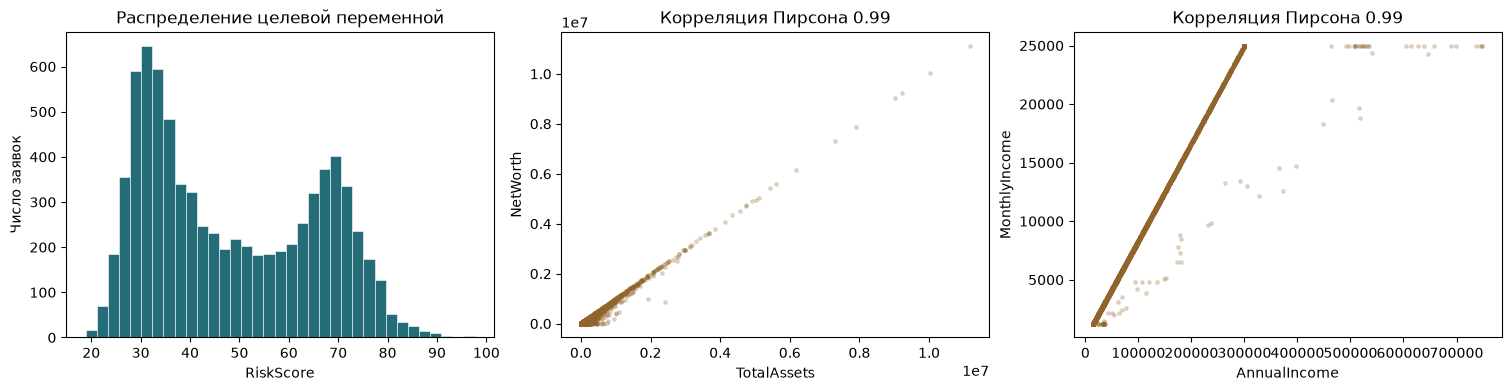

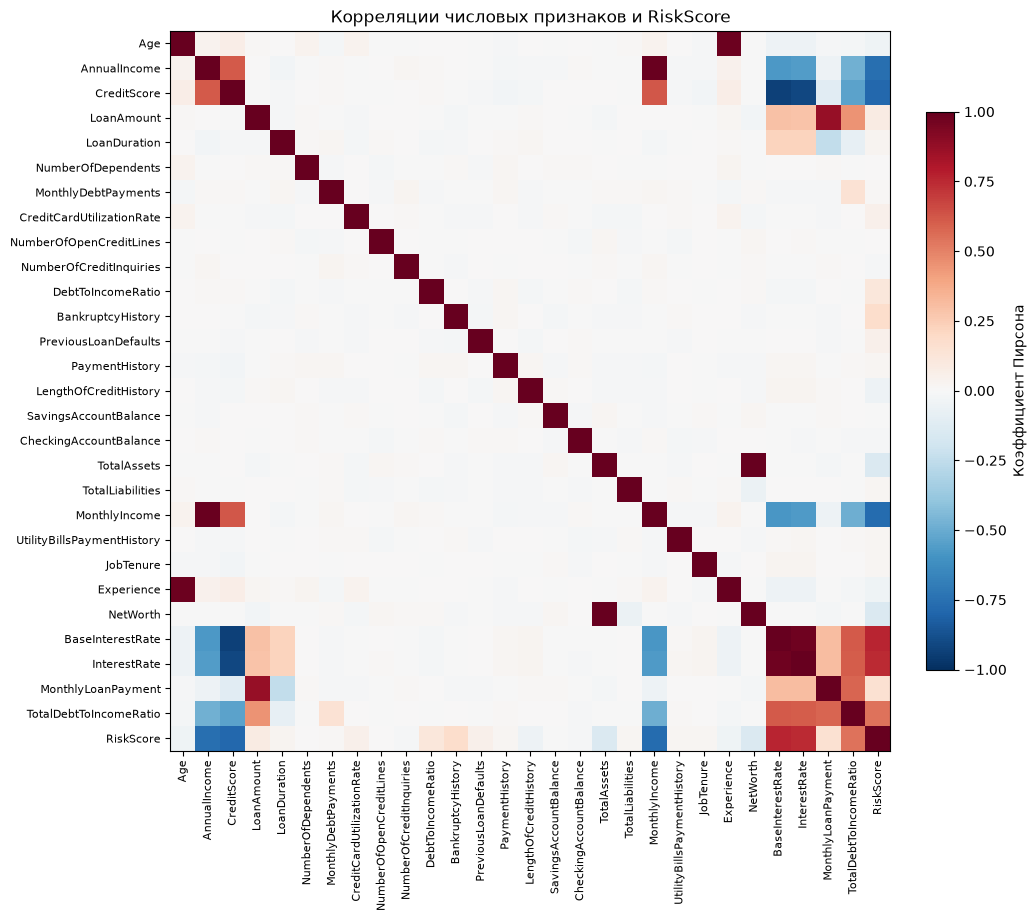

Медиана RiskScore — 44.23. Средние 50% значений лежат от 32.72 до 64.97.
Из числовых признаков самая сильная линейная связь с целью у CreditScore (r = -0.786).
Наиболее связанная пара признаков — TotalAssets и NetWorth (r = 0.993).
Они частично дублируют информацию. Веса таких столбцов могут быть неустойчивыми.


In [3]:
eda = X_dev.select_dtypes(include="number").copy()
eda[TARGET] = y_dev
corr = eda.corr()
target_corr = corr[TARGET].drop(TARGET).dropna().sort_values(key=abs, ascending=False)
feature_corr = corr.drop(index=TARGET, columns=TARGET)
pairs = feature_corr.where(np.triu(np.ones(feature_corr.shape), k=1).astype(bool)).stack()
pairs = pairs.sort_values(key=abs, ascending=False)
fig, axes = plt.subplots(1, 1 + min(2, len(pairs)), figsize=(5 * (1 + min(2, len(pairs))), 3.8),
                         squeeze=False, layout="constrained")
axes = axes[0]
axes[0].hist(y_dev, bins=35, color="#246d78", edgecolor="white", linewidth=.4)
axes[0].set(xlabel=TARGET, ylabel="Число заявок", title="Распределение целевой переменной")
for ax, ((left, right), rho) in zip(axes[1:], pairs.head(2).items()):
    ax.scatter(eda[left], eda[right], s=6, alpha=.22, color="#90642a", rasterized=True)
    ax.set(xlabel=left, ylabel=right, title=f"Корреляция Пирсона {rho:.2f}")
plt.show()

size = max(6., .32 * len(corr))
fig, ax = plt.subplots(figsize=(size + 1, size), layout="constrained")
heat = ax.imshow(corr, vmin=-1, vmax=1, cmap="RdBu_r")
ax.set_xticks(range(len(corr)), corr.columns, rotation=90, fontsize=8)
ax.set_yticks(range(len(corr)), corr.index, fontsize=8)
ax.set_title("Корреляции числовых признаков и RiskScore")
fig.colorbar(heat, ax=ax, shrink=.72, label="Коэффициент Пирсона")
plt.show()

q1, median, q3 = np.quantile(y_dev, [.25, .5, .75])
print(f"Медиана RiskScore — {median:.2f}. Средние 50% значений лежат от {q1:.2f} до {q3:.2f}.")
if len(target_corr):
    top = target_corr.index[0]
    rho = target_corr.iloc[0]
    print(f"Из числовых признаков самая сильная линейная связь с целью у {top} (r = {rho:.3f}).")
if len(pairs):
    (first, second), rho = next(iter(pairs.items()))
    print(f"Наиболее связанная пара признаков — {first} и {second} (r = {rho:.3f}).")
    if abs(rho) > .85:
        print("Они частично дублируют информацию. Веса таких столбцов могут быть неустойчивыми.")

### Связь признаков с RiskScore

Сравниваю балл риска с кредитным рейтингом, месячным доходом, ставкой и долговой нагрузкой. Для дохода и нагрузки беру логарифмическую шкалу, чтобы показать диапазон значений.

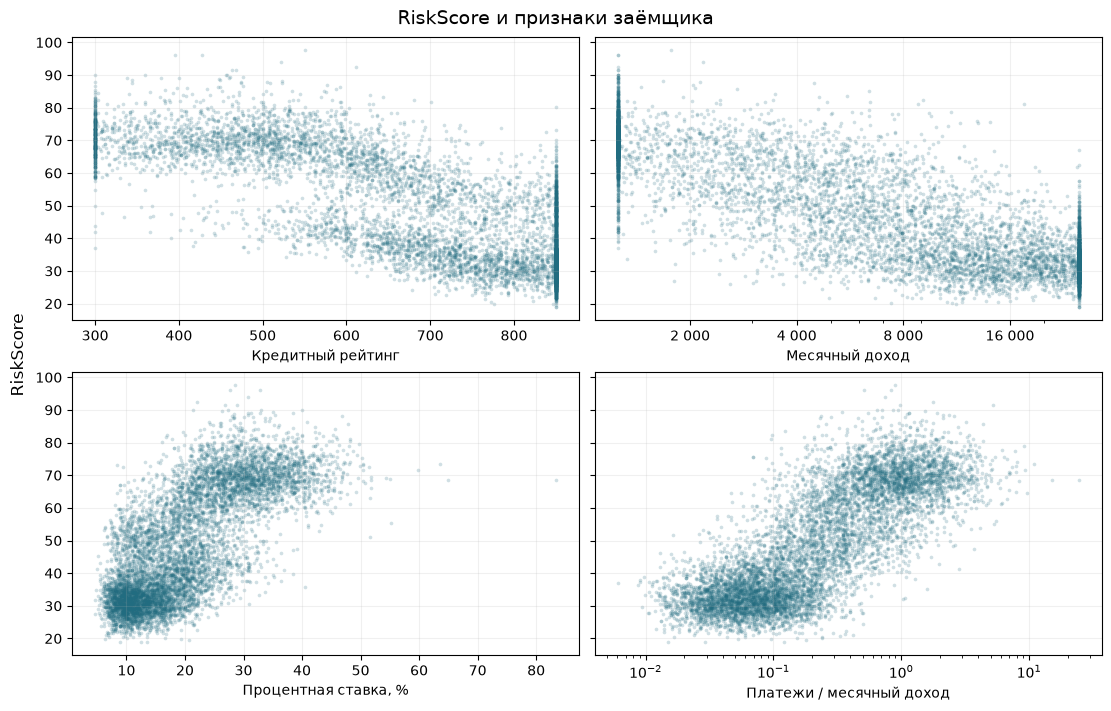

In [4]:
from matplotlib.ticker import NullFormatter

target_plots = [
    ("CreditScore", "Кредитный рейтинг", "linear"),
    ("MonthlyIncome", "Месячный доход", "log"),
    ("InterestRate", "Процентная ставка, %", "linear"),
    ("TotalDebtToIncomeRatio", "Платежи / месячный доход", "log"),
]
fig, axes = plt.subplots(2, 2, figsize=(11, 7), sharey=True, layout="constrained")
for ax, (column, label, scale) in zip(axes.flat, target_plots):
    values = X_dev[column] * 100 if column == "InterestRate" else X_dev[column]
    ax.scatter(values, y_dev, s=7, alpha=.21, linewidths=0, color="#216c80")
    ax.set(xlabel=label, xscale=scale)
    if column == "MonthlyIncome":
        ax.set_xticks([2000, 4000, 8000, 16000], ["2 000", "4 000", "8 000", "16 000"])
        ax.xaxis.set_minor_formatter(NullFormatter())
    ax.grid(alpha=.18)
fig.supylabel("RiskScore")
fig.suptitle("RiskScore и признаки заёмщика", fontsize=14)
plt.show()

По диаграммам видны два уровня RiskScore при близких значениях отдельных признаков. Поэтому в итоговой модели учитываю сочетание нескольких финансовых показателей. С баллом наиболее тесно линейно связан кредитный рейтинг. Активы и чистый капитал сильно коррелируют между собой, поэтому для итоговой шкалы использую чистый капитал.

## 2. Нормализация

Z-score вычитает среднее и делит на стандартное отклонение. Min-max вычитает минимум и делит на размах. Все параметры считаются по обучающей части, затем применяются к новым строкам. Для постоянного столбца делитель равен 1.

In [5]:
class Scaler:
    def __init__(self, method="z-score"):
        self.method = method

    def fit(self, X):
        if self.method == "z-score":
            self.offset_, scale = X.mean(axis=0), X.std(axis=0)
        elif self.method == "min-max":
            self.offset_, scale = X.min(axis=0), np.ptp(X, axis=0)
        else:
            raise ValueError("Выберите z-score или min-max")
        self.scale_ = np.where(scale == 0, 1, scale)
        return self

    def transform(self, X):
        return (X - self.offset_) / self.scale_


example = np.array([[1., 7.], [3., 7.], [5., 7.]])
new_rows = np.array([[0., 7.], [7., 9.]])
for method, baseline in [("z-score", StandardScaler()), ("min-max", MinMaxScaler())]:
    np.testing.assert_allclose(Scaler(method).fit(example).transform(new_rows),
                               baseline.fit(example).transform(new_rows))
print("Оба способа масштабирования совпали со sklearn на новых строках.")

Оба способа масштабирования совпали со sklearn на новых строках.


## 3. Метрики

MSE усредняет квадраты ошибок, MAE — их абсолютные значения. $R^2$ сравнивает квадратичную ошибку с прогнозом средним. MAPE усредняет относительные ошибки. В таблицах MAPE приведена в процентах. Реализации сверяю со sklearn, включая случаи постоянной и нулевой цели.

In [6]:
def mse(y, pred):
    return np.mean(np.square(np.asarray(y, dtype=float) - pred))


def mae(y, pred):
    return np.mean(np.abs(np.asarray(y, dtype=float) - pred))


def r2(y, pred):
    y = np.asarray(y, dtype=float)
    if len(y) < 2:
        return np.nan
    total = np.sum((y - y.mean()) ** 2)
    residual = np.sum((y - pred) ** 2)
    if total == 0:
        return float(residual == 0)
    return 1 - residual / total


def mape(y, pred):
    y = np.asarray(y, dtype=float)
    denominator = np.maximum(np.abs(y), np.finfo(float).eps)
    return np.mean(np.abs(y - pred) / denominator)


def scores(y, pred):
    return {"MSE": mse(y, pred), "MAE": mae(y, pred),
            "R²": r2(y, pred), "MAPE, %": 100 * mape(y, pred)}

In [7]:
truth = np.array([1., 2., 4.])
guess = np.array([2., 2., 2.])
own = [mse(truth, guess), mae(truth, guess), r2(truth, guess), mape(truth, guess)]
reference = [metrics.mean_squared_error(truth, guess), metrics.mean_absolute_error(truth, guess),
             metrics.r2_score(truth, guess), metrics.mean_absolute_percentage_error(truth, guess)]
np.testing.assert_allclose(own, [5/3, 1, -1/14, 0.5])
np.testing.assert_allclose(own, reference)
assert r2([3, 3], np.array([3, 3])) == 1
assert r2([3, 3], np.array([2, 2])) == 0
np.testing.assert_allclose(mape([0, 2], np.array([1., 2.])),
                           metrics.mean_absolute_percentage_error([0, 2], [1, 2]))
display(pd.DataFrame({"Своя формула": own, "sklearn": reference},
                     index=["MSE", "MAE", "R²", "MAPE (доля)"]))

,Своя формула,sklearn
MSE,1.66667,1.66667
MAE,1.00000,1.00000
R²,-0.07143,-0.07143
MAPE (доля),0.50000,0.50000


## 4. Линейная регрессия

Аналитическое решение находит коэффициенты МНК через lstsq. GD обновляет веса по градиенту всей выборки. SGD обновляет веса по одной строке и усредняет веса последних эпох. Все три метода используют модель $\hat y=b+Xw$.

Для сравнения кодирую категории индикаторами, дату — числом дней, а пропуски в числах — нулём и отдельным индикатором. Набор столбцов и параметры нормализации определяются на обучающей части.

In [8]:
class MyLinearRegression:
    def __init__(self, method="analytic", epochs=55, seed=SEED):
        self.method = method
        self.epochs = epochs
        self.seed = seed

    def fit(self, X, y, *, track_loss=False):
        X = np.asarray(X, dtype=float)
        y = np.asarray(y, dtype=float)
        center = X.mean(axis=0)
        A, target = X - center, y - y.mean()
        n, d = A.shape
        self.loss_history_ = []
        if self.method == "analytic":
            w = np.linalg.lstsq(A, target, rcond=None)[0]
        elif self.method == "gd":
            gram, rhs = (A.T @ A) / n, (A.T @ target) / n
            lipschitz = max(np.linalg.eigvalsh(gram)[-1], 1e-15)
            w = np.zeros(d)
            target_square = np.mean(target**2)
            for _ in range(self.epochs):
                gradient = gram @ w - rhs
                if np.max(np.abs(gradient)) < 1e-9:
                    break
                w -= gradient / lipschitz
                if track_loss:
                    # Раскрытый квадрат ошибки через уже вычисленные AᵀA/n и Aᵀy/n.
                    self.loss_history_.append(target_square + w @ (gram @ w - 2 * rhs))
        elif self.method == "sgd":
            rng = np.random.default_rng(self.seed)
            w, total = np.zeros(d), np.zeros(d)
            # Ограничиваем шаг с учётом самой длинной строки.
            initial_step = 0.8 / max(1., np.max(np.einsum("ij,ij->i", A, A)))
            count = 0
            for epoch in range(self.epochs):
                step = initial_step / (1 + epoch / 4)
                for i in rng.permutation(n):
                    w -= step * (A[i] @ w - target[i]) * A[i]
                if track_loss:
                    self.loss_history_.append(mse(target, A @ w))
                if epoch >= self.epochs // 2:
                    total += w
                    count += 1
            w = total / count
        else:
            raise ValueError("Неизвестный метод обучения")
        self.coef_ = w
        self.intercept_ = y.mean() - center @ w
        return self

    def predict(self, X):
        return np.asarray(X) @ self.coef_ + self.intercept_

In [9]:
# Независимые проверки на маленькой матрице с известными коэффициентами.
rng = np.random.default_rng(SEED)
mini = rng.normal(size=(90, 4))
exact_y = 3 + mini @ np.array([1., -2., 0., 0.5])
for method, epochs in [("analytic", 1), ("gd", 400), ("sgd", 100)]:
    fitted = MyLinearRegression(method, epochs).fit(mini, exact_y)
    np.testing.assert_allclose(fitted.predict(mini), exact_y, atol=1e-6)

noisy_y = exact_y + rng.normal(0, 0.3, len(mini))
print("МНК, GD и SGD воспроизвели известную линейную зависимость.")

МНК, GD и SGD воспроизвели известную линейную зависимость.


In [10]:
def encode(frame):
    parts = []
    for name in frame:
        col = frame[name]
        if name.casefold().endswith("date"):
            dates = pd.to_datetime(col, errors="coerce", utc=True)
            col = (dates - pd.Timestamp("2000-01-01", tz="UTC")).dt.total_seconds() / 86400
        if pd.api.types.is_numeric_dtype(col):
            values = col.astype(float).replace([np.inf, -np.inf], np.nan)
            parts.append(pd.DataFrame({name: values.fillna(0),
                                       name + "__missing": values.isna().astype(float)}))
        else:
            category = col.astype("string").fillna("<пропуск>")
            parts.append(pd.get_dummies(category, prefix=name, dtype=float))
    return pd.concat(parts, axis=1)


class Features:
    def __init__(self, scaling="z-score", basis="base"):
        self.scaler = Scaler(scaling)
        self.basis = basis

    def encode(self, frame):
        if self.basis == "financial":
            return encode_financial(frame)
        return encode(frame)

    def fit(self, frame):
        encoded = self.encode(frame)
        self.columns = encoded.columns[encoded.nunique() > 1]
        if not len(self.columns):
            raise ValueError("Не найдено ни одного изменяющегося признака")
        self.scaler.fit(encoded[self.columns].to_numpy(dtype=float))
        return self

    def transform(self, frame):
        encoded = self.encode(frame).reindex(columns=self.columns, fill_value=0)
        result = self.scaler.transform(encoded.to_numpy(dtype=float))
        if self.basis == "financial":
            # Масштаб столбца после z-score задаёт силу L2-штрафа для его коэффициента.
            result[:, self.columns.str.startswith("поправка · ")] *= np.sqrt(.002)
            result[:, self.columns == "поправка · возраст"] *= np.sqrt(3.5)
            result[:, self.columns == "возраст 30–50"] *= np.sqrt(.002 / .4)
        return result


def prepare(train_x, valid_x, method="z-score", basis="base"):
    preprocessing = Features(method, basis=basis).fit(train_x)
    return preprocessing.transform(train_x), preprocessing.transform(valid_x)

### Сравнение со sklearn

Сравниваю прогнозы и время обучения трёх реализаций на одном разбиении. Для МНК использую LinearRegression, для стохастического спуска — SGDRegressor. Аналитическое решение также проверяю с обоими способами нормализации.

In [11]:
A, B = prepare(X_dev, X_hold)
models = {
    "Своя · аналитическая": MyLinearRegression(),
    "Своя · GD": MyLinearRegression("gd", epochs=12000),
    "Своя · SGD": MyLinearRegression("sgd", epochs=120),
    "sklearn · LinearRegression": LinearRegression(),
    "sklearn · SGDRegressor": SGDRegressor(
        penalty=None, alpha=.0001, learning_rate="invscaling", eta0=.005,
        average=True, max_iter=150, tol=None, random_state=SEED),
}
hold_predictions = {}
rows = {}
for name, model in models.items():
    start = perf_counter()
    hold_predictions[name] = model.fit(A, y_dev).predict(B)
    rows[name] = {**scores(y_hold, hold_predictions[name]), "Секунды": perf_counter() - start}
reference_prediction = hold_predictions["sklearn · LinearRegression"]
for name in models:
    rows[name]["MAE к прогнозу sklearn OLS"] = mae(reference_prediction, hold_predictions[name])
rows["Среднее на train"] = scores(y_hold, np.full(len(y_hold), y_dev.mean()))
display(pd.DataFrame(rows).T)
np.testing.assert_allclose(hold_predictions["Своя · аналитическая"], reference_prediction,
                           rtol=1e-7, atol=1e-6)

# Повторяем аналитическое обучение при min-max масштабировании.
A_min, B_min = prepare(X_dev, X_hold, method="min-max")
minmax_prediction = MyLinearRegression().fit(A_min, y_dev).predict(B_min)
print(f"MSE при min-max: {mse(y_hold, minmax_prediction):.5f}; "
      f"при z-score: {mse(y_hold, reference_prediction):.5f}.")

,MSE,MAE,R²,"MAPE, %",Секунды,MAE к прогнозу sklearn OLS
Своя · аналитическая,55.68433,5.95837,0.81685,13.95843,0.01228,0.00000
Своя · GD,55.69842,5.95904,0.81680,13.95921,0.05491,0.02002
Своя · SGD,55.75282,5.96118,0.81662,13.95883,2.14622,0.13909
sklearn · LinearRegression,55.68433,5.95837,0.81685,13.95843,0.01402,0.00000
sklearn · SGDRegressor,55.68460,5.96411,0.81685,13.95650,0.18825,0.10726
Среднее на train,304.11215,15.65908,-0.00025,36.55197,NaN,NaN


MSE при min-max: 55.68433; при z-score: 55.68433.


### Сходимость GD и SGD

Сравниваю обучающий MSE итерационных методов с минимумом аналитического МНК на тех же стандартизированных признаках. У GD шаг использует всю выборку. Для SGD одна точка соответствует концу эпохи и показывает ошибку текущих весов до их финального усреднения. Шкалы MSE подобраны отдельно для каждой панели. Замеры времени выше сделаны без записи истории обучения.

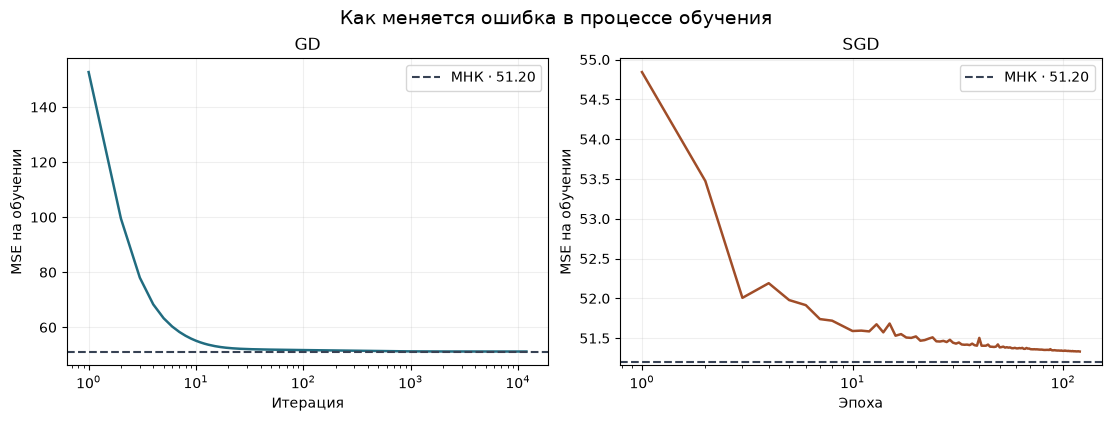

In [12]:
train_ols_mse = mse(y_dev, models["Своя · аналитическая"].predict(A))
fig, axes = plt.subplots(1, 2, figsize=(11, 4.1), layout="constrained")
for ax, method, label, axis_label, color in zip(
    axes, ("gd", "sgd"), ("GD", "SGD"), ("Итерация", "Эпоха"), ("#216c80", "#a04d28"),
):
    epochs = models[f"Своя · {label}"].epochs
    traced = MyLinearRegression(method, epochs=epochs).fit(A, y_dev, track_loss=True)
    np.testing.assert_allclose(traced.coef_, models[f"Своя · {label}"].coef_, atol=1e-10)
    losses = traced.loss_history_
    ax.plot(np.arange(1, len(losses) + 1), losses, color=color, linewidth=1.8)
    ax.axhline(train_ols_mse, linestyle="--", color="#374254", label=f"МНК · {train_ols_mse:.2f}")
    ax.set(title=label, xlabel=axis_label, ylabel="MSE на обучении", xscale="log")
    ax.grid(alpha=.2)
    ax.legend()
fig.suptitle("Как меняется ошибка в процессе обучения", fontsize=14)
plt.show()

## 5. Кросс-валидация

В k-fold каждая строка один раз попадает в проверочный фолд. В leave-one-out размер проверочного фолда равен одной строке. Для обычного МНК со свободным членом использую формулу PRESS: остаток при исключении строки равен $e_i/(1-h_{ii})$. Диагональ проектора вычисляю через SVD и сверяю прогнозы с прямым переобучением. Сравниваю качество и время обоих способов на одних данных.

In [13]:
def kfold_indices(n, k=5, seed=SEED):
    if not 2 <= k <= n:
        raise ValueError("Требуется 2 ≤ k ≤ n")
    folds = np.array_split(np.random.default_rng(seed).permutation(n), k)
    for i, valid in enumerate(folds):
        yield np.concatenate(folds[:i] + folds[i+1:]), valid


def leave_one_out_indices(n):
    indices = np.arange(n)
    for i in range(n):
        yield np.concatenate([indices[:i], indices[i+1:]]), indices[i:i+1]


def cross_predict(frame, y, splits, factory):
    prediction = np.empty(len(y))
    fold_scores = []
    for train, valid in splits:
        A, B = prepare(frame.iloc[train], frame.iloc[valid])
        prediction[valid] = factory().fit(A, y[train]).predict(B)
        fold_scores.append(mse(y[valid], prediction[valid]))
    return prediction, fold_scores

In [14]:
def loo_ols(frame, y):
    features = Features().fit(frame)
    X = features.transform(frame)
    design = np.column_stack([np.ones(len(X)), X])
    U, singular, _ = np.linalg.svd(design, full_matrices=False)
    tol = np.finfo(float).eps * max(design.shape) * singular[0]
    basis = U[:, singular > tol]
    fitted = basis @ (basis.T @ y)
    leverage = np.einsum("ij,ij->i", basis, basis)
    regular = (1 - leverage) > 1e-8
    pred = np.empty_like(y, dtype=float)
    pred[regular] = y[regular] - (y[regular] - fitted[regular]) / (1 - leverage[regular])
    for i in np.flatnonzero(~regular):
        keep = np.arange(len(y)) != i
        A, B = prepare(frame.iloc[keep], frame.iloc[[i]])
        pred[i] = MyLinearRegression().fit(A, y[keep]).predict(B)[0]
    return pred


mini_frame = pd.DataFrame(mini[:32], columns=list("abcd"))
mini_frame["тип"] = ["А", "Б"] * 15 + ["А", "редкая"]
mini_frame.loc[[2, 5], "b"] = np.nan
parts = list(kfold_indices(32))
np.testing.assert_array_equal(np.sort(np.concatenate([v for _, v in parts])), np.arange(32))
assert all(not np.intersect1d(t, v).size for t, v in parts)
direct, _ = cross_predict(mini_frame, noisy_y[:32], leave_one_out_indices(32), MyLinearRegression)
np.testing.assert_allclose(loo_ols(mini_frame, noisy_y[:32]), direct, atol=1e-8)
print("Разбиения k-fold корректны. Быстрый LOO совпал с 32 отдельными переобучениями.")

Разбиения k-fold корректны. Быстрый LOO совпал с 32 отдельными переобучениями.


In [15]:
start = perf_counter()
ols_oof, fold_mse = cross_predict(X_dev, y_dev, kfold_indices(len(y_dev)), MyLinearRegression)
kfold_seconds = perf_counter() - start

start = perf_counter()
loo_prediction = loo_ols(X_dev, y_dev)
loo_seconds = perf_counter() - start

print("MSE базового МНК по пяти фолдам:", np.round(fold_mse, 4))
display(pd.DataFrame([
    {"Метод проверки": "5-fold", **scores(y_dev, ols_oof), "Секунды": kfold_seconds},
    {"Метод проверки": "LOO (PRESS)", **scores(y_dev, loo_prediction), "Секунды": loo_seconds},
]).set_index("Метод проверки"))

MSE базового МНК по пяти фолдам: [54.7836 51.6281 51.7636 50.3042 52.5159]


,MSE,MAE,R²,"MAPE, %",Секунды
Метод проверки,,,,,
5-fold,52.19910,5.78264,0.82317,13.59539,0.36082
LOO (PRESS),52.09138,5.77989,0.82353,13.59426,0.08012


## 6. Регуляризация

Для стандартизированных признаков минимизирую $\|y-b-Xw\|^2/(2n) + \lambda_1\sum |w_j| + (\lambda_p/p)\sum |w_j|^p$. Выбор $p=2$ даёт квадратичный штраф, сочетание с $\lambda_1$ — Elastic Net. При $p=1$ штраф сводится к L1. Свободный член не штрафуется. Параметр `p` задаёт пользователь, здесь рассматривается выпуклая задача $p\ge 1$.

Для L1 и Elastic Net записываю каждый вес как разность двух неотрицательных частей. Тогда L1-штраф равен сумме этих частей в минимуме. Для задачи с границами задаю собственную функцию потерь и градиент и использую L-BFGS-B. Для чистого L2 решаю систему линейных уравнений, для общего гладкого Lp передаю в SciPy собственные формулы функции потерь и градиента. Ниже сравниваю решения со sklearn, а для дробного $p$ проверяю градиент конечными разностями.

In [16]:
class RegularizedRegression:
    def __init__(self, l1=0., lp=0., p=2.):
        if min(l1, lp) < 0 or p < 1:
            raise ValueError("Требуется l1, lp ≥ 0 и p ≥ 1")
        self.l1, self.lp, self.p = l1, lp, p

    def smooth_loss(self, w, A, y):
        error = A @ w - y
        loss = (error @ error) / (2 * len(y)) + self.lp * np.sum(abs(w)**self.p) / self.p
        grad = A.T @ error / len(y) + self.lp * np.sign(w) * abs(w)**(self.p - 1)
        return loss, grad

    def fit(self, X, y):
        X, y = np.asarray(X, dtype=float), np.asarray(y, dtype=float)
        center = X.mean(axis=0)
        A, target = X - center, y - y.mean()
        n, d = A.shape
        l1 = self.l1 + (self.lp if self.p == 1 else 0.)
        l2 = self.lp if self.p == 2 else 0.
        if self.p not in (1, 2) and self.lp > 0:
            if l1 > 0:
                raise ValueError("Для сочетания L1 и Lp используйте p=2 (Elastic Net)")
            result = minimize(self.smooth_loss, np.zeros(d), args=(A, target), jac=True,
                              method="L-BFGS-B", options={"maxiter": 3000, "ftol": 1e-14, "gtol": 1e-8})
            if not result.success:
                raise RuntimeError(result.message)
            w = result.x
        elif l1 > 0:
            gram, rhs = A.T @ A / n, A.T @ target / n
            # w = positive - negative, обе части неотрицательны.
            # При l1 > 0 в минимуме они не могут одновременно быть положительными.
            def split_loss(parts):
                w = parts[:d] - parts[d:]
                grad = gram @ w - rhs + l2 * w
                value = .5 * w @ (gram @ w) - rhs @ w + .5 * l2 * (w @ w) + l1 * parts.sum()
                return value, np.r_[grad + l1, -grad + l1]

            result = minimize(split_loss, np.zeros(2*d), jac=True, method="L-BFGS-B",
                              bounds=[(0., None)] * (2*d),
                              options={"maxiter": 5000, "maxfun": 15000, "ftol": 1e-14, "gtol": 1e-8})
            if not result.success:
                raise RuntimeError(result.message)
            w = result.x[:d] - result.x[d:]
        elif l2 > 0:
            w = np.linalg.solve(A.T @ A + n * l2 * np.eye(d), A.T @ target)
        else:
            w = np.linalg.lstsq(A, target, rcond=None)[0]
        self.coef_, self.intercept_ = w, y.mean() - center @ w
        return self

    def predict(self, X):
        return np.asarray(X) @ self.coef_ + self.intercept_

In [17]:
for model, ref in [(RegularizedRegression(l1=.1), Lasso(alpha=.1, tol=1e-10)),
                   (RegularizedRegression(lp=.1), Ridge(alpha=len(mini) * .1)),
                   (RegularizedRegression(l1=.06, lp=.04), ElasticNet(alpha=.1, l1_ratio=.6, tol=1e-10)),
                   (RegularizedRegression(lp=.1, p=1), Lasso(alpha=.1, tol=1e-10))]:
    np.testing.assert_allclose(model.fit(mini, noisy_y).predict(mini),
                               ref.fit(mini, noisy_y).predict(mini), atol=1e-6)
lp_test = RegularizedRegression(lp=.1, p=1.5)
point = np.array([-2., .4, 1.3, -.3])
steps = np.eye(len(point)) * 1e-6
numeric_grad = [(lp_test.smooth_loss(point+h, mini, noisy_y)[0]
                 - lp_test.smooth_loss(point-h, mini, noisy_y)[0]) / 2e-6 for h in steps]
np.testing.assert_allclose(lp_test.smooth_loss(point, mini, noisy_y)[1], numeric_grad, atol=1e-7)
lp_test.fit(mini, noisy_y)
_, grad = lp_test.smooth_loss(lp_test.coef_, mini-mini.mean(0), noisy_y-noisy_y.mean())
assert np.max(abs(grad)) < 1e-5
print("L1, L2 и Elastic Net совпали со sklearn. Градиент Lp прошёл численную проверку.")

L1, L2 и Elastic Net совпали со sklearn. Градиент Lp прошёл численную проверку.


In [18]:
P = 1.5
penalty_strengths = (.001, .01, .1)
candidates = {}
for alpha in penalty_strengths:
    candidates.update({
        f"L1 λ={alpha}": {"l1": alpha},
        f"L2 λ={alpha}": {"lp": alpha},
        f"Elastic Net λ={alpha}": {"l1": alpha / 2, "lp": alpha / 2},
        f"Lp p={P}, λ={alpha}": {"lp": alpha, "p": P},
    })

def candidate_model(name):
    return RegularizedRegression(**candidates[name])

oof = {name: np.empty(len(y_dev)) for name in candidates}
for tr, va in kfold_indices(len(y_dev)):
    fold_train, fold_valid = prepare(X_dev.iloc[tr], X_dev.iloc[va])
    for name in candidates:
        oof[name][va] = candidate_model(name).fit(fold_train, y_dev[tr]).predict(fold_valid)

metrics_by_penalty = {name: scores(y_dev, prediction) for name, prediction in oof.items()}
cv_table = pd.DataFrame({"МНК": scores(y_dev, ols_oof), **metrics_by_penalty}).T.sort_values("MSE")
display(cv_table)

,MSE,MAE,R²,"MAPE, %"
L1 λ=0.01,52.15765,5.78243,0.82331,13.59805
L1 λ=0.001,52.18502,5.78259,0.82321,13.59599
Elastic Net λ=0.001,52.18958,5.78320,0.82320,13.59643
"Lp p=1.5, λ=0.001",52.19042,5.78306,0.82319,13.59660
"Lp p=1.5, λ=0.01",52.19101,5.78464,0.82319,13.59867
L2 λ=0.001,52.19662,5.78373,0.82317,13.59681
L1 λ=0.1,52.19688,5.78741,0.82317,13.61382
МНК,52.19910,5.78264,0.82317,13.59539
Elastic Net λ=0.01,52.21587,5.78715,0.82311,13.60336
L2 λ=0.01,52.28595,5.79155,0.82287,13.60839


### Как сила штрафа влияет на ошибку и веса

На первом графике показан MSE на прогнозах пяти фолдов. На втором — евклидова норма коэффициентов модели, обученной на всей выборке разработки. Сравнение использует те же исходные признаки и те же значения λ, что и в таблице выше.

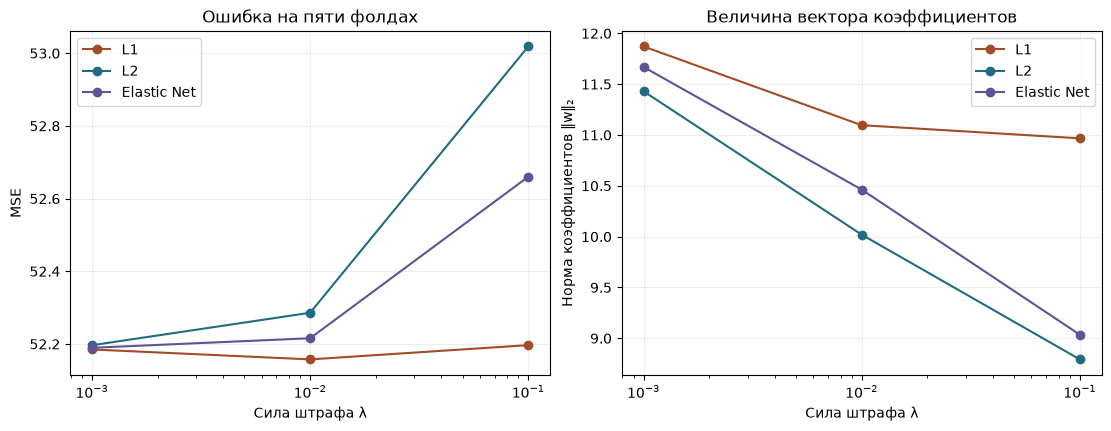

In [19]:
regularization_x = Features().fit(X_dev).transform(X_dev)
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), layout="constrained")
for penalty, color in [("L1", "#a04d28"), ("L2", "#216c80"), ("Elastic Net", "#645094")]:
    names = [f"{penalty} λ={strength}" for strength in penalty_strengths]
    errors = cv_table.loc[names, "MSE"].to_numpy()
    norms = [
        np.linalg.norm(candidate_model(name).fit(regularization_x, y_dev).coef_)
        for name in names
    ]
    for ax, values in zip(axes, (errors, norms)):
        ax.plot(penalty_strengths, values, marker="o", label=penalty, color=color)
axes[0].set(title="Ошибка на пяти фолдах", ylabel="MSE")
axes[1].set(title="Величина вектора коэффициентов", ylabel="Норма коэффициентов ‖w‖₂")
for ax in axes:
    ax.set(xlabel="Сила штрафа λ", xscale="log")
    ax.grid(alpha=.2)
    ax.legend()
plt.show()

## 7. Итоговая модель для Kaggle

**Финансовые признаки.** Считаю, сколько границ пересекает заявка на каждой из шести шкал: рейтинг, доход, капитал, кредитная история, доля долга и использование карты. Например, годовой доход 85 000 пересекает границы 30 000, 50 000 и 80 000. Сводный индекс учитывает сочетание дохода, суммы кредита, капитала, ставки, нагрузки и кредитной истории. Плавные функции индекса меняют вклад шкал и дополнительных признаков в области перехода. Среди поправок есть две возрастные группы: 30–55 и 30–50 лет.

**Пропуски.** Использую аннуитетную формулу для восстановления суммы кредита и соотношение между общими платежами и доходом для восстановления текущего ежемесячного долга. Базовая ставка, сумма и срок дают оценку CreditScore. Если одновременно отсутствуют чистый капитал и история банкротства, усредняю числовые признаки по 21 фиксированному сценарию.

**Обучение.** Фиксированные преобразования дают 26 числовых столбцов. Одна линейная регрессия обучает их коэффициенты с L2-штрафом. После стандартизации масштабирую дополнительные столбцы, чтобы ограничить вклад соответствующих коэффициентов. Коэффициенты внутри формул построения признаков подбирались по размеченным данным, поэтому локальные оценки могут быть оптимистичны.

In [20]:
def recover_financial_values(frame):
    result = frame.copy()
    monthly_rate = frame.InterestRate / 12
    factor = -np.expm1(-frame.LoanDuration * np.log1p(monthly_rate)) / monthly_rate
    principal = frame.MonthlyLoanPayment * factor
    monthly_debt = frame.MonthlyIncome * frame.TotalDebtToIncomeRatio - frame.MonthlyLoanPayment
    result["LoanAmount"] = frame.LoanAmount.fillna(principal)
    result["MonthlyDebtPayments"] = frame.MonthlyDebtPayments.fillna(monthly_debt)
    # При отсутствующей базовой ставке фактическая ставка даёт только приближение.
    result["BaseInterestRate"] = frame.BaseInterestRate.fillna(frame.InterestRate)
    credit = (.465 + 1e-6 * result.LoanAmount + frame.LoanDuration / 1200 - result.BaseInterestRate) / .0005
    result["CreditScore"] = frame.CreditScore.fillna(credit.clip(300, 850))
    return result


def scorecard_fields(frame):
    income = 12 * frame.MonthlyIncome
    bankrupt = frame.BankruptcyHistory.fillna(.05)
    employed = (frame.EmploymentStatus == "Employed").astype(float)
    scales = {
        "рейтинг": (frame.CreditScore, [600, 650, 700, 750]),
        "доход": (income, [30000, 50000, 80000, 120000]),
        "капитал": (frame.NetWorth, [50000, 100000, 250000, 500000, 1000000]),
        "история": (frame.LengthOfCreditHistory, [3, 5, 7, 10]),
        "долг": (frame.DebtToIncomeRatio, [.2, .3, .4, .5]),
        "карта": (frame.CreditCardUtilizationRate, [.2, .4, .6, .8]),
    }
    counts = pd.DataFrame({name: sum((values >= boundary).astype(float) for boundary in boundaries)
                           for name, (values, boundaries) in scales.items()}, index=frame.index)
    points = (74 - 4 * counts["рейтинг"] - 2.5 * counts["доход"] - 2 * counts["капитал"]
              - counts["история"] + 2.2 * counts["долг"] + 1.4 * counts["карта"]
              + 13.5 * bankrupt + 2.8 * frame.PreviousLoanDefaults - 3.1 * employed)
    counts["банкротство"] = bankrupt
    counts["дефолты"] = frame.PreviousLoanDefaults
    counts["занятость"] = employed
    return counts, points


def financial_profile(frame):
    income = 12 * frame.MonthlyIncome / 100000
    amount = frame.LoanAmount / 30000
    wealth = frame.NetWorth.fillna(75000) / 200000
    credit = (frame.CreditScore - 650) / 100
    rate = 10 * (frame.InterestRate - .20)
    burden = frame.TotalDebtToIncomeRatio
    duration = (frame.LoanDuration - 48) / 36
    bankruptcy = frame.BankruptcyHistory.fillna(.05)
    education = frame.EducationLevel.map({"High School": -1, "Associate": 0, "Bachelor": 1,
                                          "Master": 2, "Doctorate": 3}).fillna(0)
    age_band = frame.Age.between(30, 55).astype(float)
    high_rate = (frame.InterestRate >= .20).astype(float)

    financial = (.66 * income - .20 * amount.clip(upper=10) + .25 * wealth.clip(upper=10)
                 - .26 * credit - .62 * rate - 1.09 * burden.clip(upper=10))
    history = (-.45 * bankruptcy - .08 * frame.PreviousLoanDefaults
               + .085 * (frame.LengthOfCreditHistory - 15) / 10
               + .055 * 5 * (frame.CreditCardUtilizationRate - .30)
               - .17 * (frame.EmploymentStatus == "Unemployed") + .067 * education
               + .03 * (frame.PaymentHistory - 24) / 5 + .15 * (frame.UtilityBillsPaymentHistory - .8)
               + .02 * (frame.Age - 40) / 15 + .03 * duration)
    adjustment = (.105 * age_band - .10 * high_rate + .065 * frame.CreditScore.between(675, 799)
                  - .018 * (frame.NumberOfCreditInquiries - 1) - .012 * (frame.NumberOfDependents - 2)
                  + .035 * (frame.HomeOwnershipStatus == "Own") - .055)
    margin = financial + history + .20 * adjustment - .315
    # Фиксированные поправки в индексе перед построением признаков.
    individual = (.03 * ((frame.PaymentHistory - 24) / 5).clip(-5, 6)
                  + .03 * (5 * (frame.UtilityBillsPaymentHistory - .8)).clip(-5, 6)
                  + .02 * ((frame.Age - 40) / 15).clip(-5, 6)
                  + .055 * (5 * (frame.CreditCardUtilizationRate - .3)).clip(-5, 6)
                  + .03 * duration.clip(-5, 6))
    margin += (.4 - 1.) * individual
    default_effect = -.45 * bankruptcy - .08 * frame.PreviousLoanDefaults
    debt_effect = -1.09 * (burden.clip(upper=2) - .25)
    margin -= .25 * default_effect + .12 * debt_effect
    level = ndtr(margin / .31)
    counts, points = scorecard_fields(frame)
    multiplier = 1 - .30 * level
    base = pd.concat([(points * multiplier).rename("сводный балл"), level.rename("уровень"),
                      counts.mul(multiplier, axis=0)], axis=1)
    for shift in (-.15, .15):
        base[f"переход {shift}"] = points * ndtr((margin - shift) / .31)

    center = np.exp(-.5 * (margin / .34)**2) * points / 60
    extra = pd.DataFrame({
        "доход": income.clip(upper=4), "сумма": amount.clip(upper=5),
        "капитал": (frame.NetWorth.fillna(55000) / 200000).clip(upper=6),
        "нагрузка": burden.clip(upper=2), "рейтинг": credit,
        "надбавка к ставке": 10 * (frame.InterestRate / frame.BaseInterestRate - 1),
        "срок": duration, "дефолты": frame.PreviousLoanDefaults, "банкротство": bankruptcy,
        "возраст": age_band, "ставка": high_rate, "образование": education,
    }, index=frame.index).clip(-5, 6)
    result = pd.concat([base, extra.mul(center, axis=0).add_prefix("поправка · ")], axis=1)
    result["возраст 30–50"] = frame.Age.between(30, 50).astype(float) * center
    return result


def encode_financial(raw_frame):
    """При совместном пропуске усредняем признаки по 21 фиксированному сценарию."""
    frame = recover_financial_values(raw_frame)
    values = financial_profile(frame)
    missing = frame.NetWorth.isna() & frame.BankruptcyHistory.isna()
    if not missing.any():
        return values
    credit_missing = raw_frame.CreditScore.isna()
    subset = frame.loc[missing]
    n = 21
    order = np.arange(n)
    assets = np.exp(np.log(61000) + 1.28*ndtri((order+.5)/n))
    rate_factors = np.clip(1 + .1*ndtri(((8*order % n)+.5)/n), .8, 1.2)
    total = np.zeros((len(subset), values.shape[1]))
    for j in order:
        scenario = subset.copy()
        balance = assets[j] - subset.TotalLiabilities
        scenario["NetWorth"] = balance.where(balance > 0, 6000)
        scenario["BankruptcyHistory"] = float(j == n//2)
        estimated_credit = (.465 + 1e-6*subset.LoanAmount + subset.LoanDuration/1200
                            - subset.InterestRate/rate_factors[j]) / .0005
        scenario["CreditScore"] = subset.CreditScore.where(~credit_missing.loc[missing],
                                                         estimated_credit.clip(300, 850))
        total += financial_profile(scenario).to_numpy()
    values.loc[missing] = total / n
    return values

In [21]:
# Проверяем связи на доступных исходных данных выборки разработки.
known = X_dev.dropna().copy()
masked = known.copy()
masked[["LoanAmount", "MonthlyDebtPayments", "CreditScore"]] = np.nan
restored = recover_financial_values(masked)
for col in ("LoanAmount", "MonthlyDebtPayments", "CreditScore"):
    np.testing.assert_allclose(restored[col], known[col], rtol=1e-9, atol=1e-6)
print("Для заполненных заявок с известной базовой ставкой три формулы воспроизводят исходные значения.")

Для заполненных заявок с известной базовой ставкой три формулы воспроизводят исходные значения.


### Проверка качества

Сравниваю базовый МНК и итоговую модель на одних отложенных заявках. Поскольку Kaggle-тест заполнен полностью, отдельно привожу результат на заполненных анкетах. Для итоговой модели также считаю ошибку на пяти фолдах: каждая строка оценивается по прогнозу модели, которая училась на остальных фолдах.

In [22]:
FINAL_L2 = .002
complete_hold = X_hold.notna().all(axis=1).to_numpy()
full_complete = X.notna().all(axis=1).to_numpy()
final_train, final_valid = prepare(X_dev, X_hold, basis="financial")
hold_prediction = RegularizedRegression(lp=FINAL_L2).fit(final_train, y_dev).predict(final_valid)

cv_prediction = np.empty(len(y))
for tr, va in kfold_indices(len(y), k=5, seed=117):
    fold_train, fold_valid = prepare(X.iloc[tr], X.iloc[va], basis="financial")
    cv_prediction[va] = RegularizedRegression(lp=FINAL_L2).fit(fold_train, y[tr]).predict(fold_valid)

comparisons = [
    ("Отложенная часть, заполненные", "Базовый МНК",
     y_hold[complete_hold], hold_predictions["Своя · аналитическая"][complete_hold]),
    ("Отложенная часть, заполненные", "Итоговая L2", y_hold[complete_hold], hold_prediction[complete_hold]),
    ("Отложенная часть, все заявки", "Итоговая L2", y_hold, hold_prediction),
    ("Пять фолдов, заполненные", "Итоговая L2", y[full_complete], cv_prediction[full_complete]),
]
display(pd.DataFrame([
    {"Проверка": label, "Модель": name, "Строк": len(target), **scores(target, prediction)}
    for label, name, target, prediction in comparisons
]))

,Проверка,Модель,Строк,MSE,MAE,R²,"MAPE, %"
0,"Отложенная часть, заполненные",Базовый МНК,1868,54.87166,5.92678,0.81994,13.89392
1,"Отложенная часть, заполненные",Итоговая L2,1868,18.75208,2.98618,0.93846,6.85530
2,"Отложенная часть, все заявки",Итоговая L2,1958,20.30315,3.07719,0.93322,7.06214
3,"Пять фолдов, заполненные",Итоговая L2,9332,18.08483,2.95410,0.93917,6.85437


### Фактический балл, прогноз и остатки

Проверяю прогнозы на 1 868 отложенных заявках без пропусков. На левой диаграмме диагональ соответствует точному прогнозу. Справа остаток равен факту минус прогноз. Линия показывает средний остаток в десяти группах, образованных по величине прогноза. Положительный средний остаток означает занижение риска в группе.

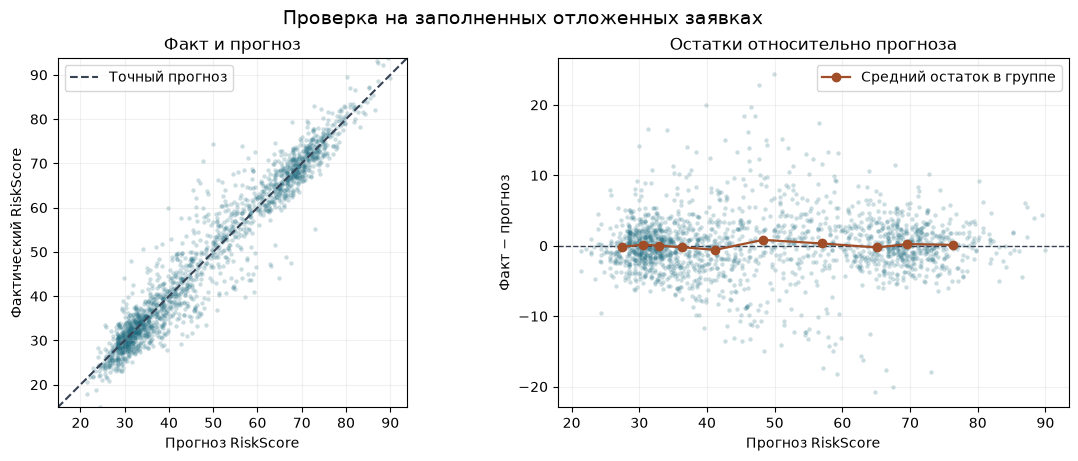

In [23]:
actual = y_hold[complete_hold]
predicted = hold_prediction[complete_hold]
residual = actual - predicted
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), layout="constrained")
bounds = [min(actual.min(), predicted.min()), max(actual.max(), predicted.max())]
axes[0].scatter(predicted, actual, s=10, alpha=.23, linewidths=0, color="#216c80")
axes[0].plot(bounds, bounds, linestyle="--", color="#374254", label="Точный прогноз")
axes[0].set(title="Факт и прогноз", xlabel="Прогноз RiskScore", ylabel="Фактический RiskScore",
            xlim=bounds, ylim=bounds, aspect="equal")
axes[0].legend()

axes[1].scatter(predicted, residual, s=10, alpha=.23, linewidths=0, color="#216c80")
axes[1].axhline(0, linestyle="--", color="#374254", linewidth=1)
residuals = pd.DataFrame({"прогноз": predicted, "остаток": residual})
groups = pd.qcut(residuals["прогноз"], 10, duplicates="drop")
means = residuals.groupby(groups, observed=True).mean()
axes[1].plot(means["прогноз"], means["остаток"], color="#a04d28", marker="o",
             linewidth=1.6, label="Средний остаток в группе")
axes[1].set(title="Остатки относительно прогноза", xlabel="Прогноз RiskScore",
            ylabel="Факт − прогноз")
axes[1].legend(loc="upper right")
for ax in axes:
    ax.grid(alpha=.18)
fig.suptitle("Проверка на заполненных отложенных заявках", fontsize=14)
plt.show()

## 8. Финальное обучение и посылка

Обучаю линейную регрессию на всех 9 788 размеченных заявках. Для 5 000 строк test получаю прогнозы и записываю их по ID в порядке шаблона ex.csv. Посылка прошла проверку на Kaggle. Приведённые в ноутбуке оценки рассчитаны на размеченных данных.

In [24]:
all_features = Features(basis="financial").fit(X)
final_model = RegularizedRegression(lp=FINAL_L2).fit(all_features.transform(X), y)
test_prediction = final_model.predict(all_features.transform(test[features]))
assert len(test_prediction) == len(test) and np.isfinite(test_prediction).all()

# ex.csv задаёт формат и порядок строк. Его примерные значения RiskScore не используются.
submission = pd.read_csv(data_dir / "ex.csv")
assert submission.columns.tolist() == ["ID", TARGET]
assert submission.ID.is_unique and test.ID.is_unique and len(submission) == len(test)
assert set(submission.ID) == set(test.ID)
submission[TARGET] = submission.ID.map(pd.Series(test_prediction, index=test.ID))
destination = LAB / "submission.csv"
submission.to_csv(destination, index=False)
check = pd.read_csv(destination)
np.testing.assert_array_equal(check.ID, submission.ID)
np.testing.assert_allclose(check[TARGET], submission[TARGET])
display(check.head())
print(f"Сохранено {len(check):,} прогнозов в {destination}.")

,ID,RiskScore
0,0,33.05435
1,1,53.92629
2,2,30.13120
3,3,34.68245
4,4,33.31727


Сохранено 5,000 прогнозов в lab1\submission.csv.


## Требования и проверки

| Пункт задания | Баллы по условию | Где выполнено |
|---|---:|---|
| EDA: распределение цели, связи признаков, корреляции и выводы | 1 | § 1 |
| Z-score и min-max со сверкой со sklearn | 1 | § 2 |
| MSE, MAE, R² и MAPE со сверкой со sklearn | 2 | § 3 |
| МНК, GD и SGD, сравнение со sklearn и графики сходимости | 3 | § 4 |
| K-fold и leave-one-out, метрики и время проверки | 3 | § 5 |
| L1, L2 и Elastic Net, численная сверка и сравнение штрафов | +2 | § 6 |
| Lp с пользовательским параметром p, проверка градиента и сходимости | +1 | § 6 |
| Итоговая модель и экспорт CSV | Допуск | § 7–8 |